# 과제1. 마케팅 트렌드 분석 및 초안 검수 워크플로우
- 실습 목표 : State 정의, Graph Routing, Evaluator-Optimizer 패턴 구현
- 흐름 : `init_context` → `writer` → `evaluator` → (기준 미달: `writer` 재작성 / 기준 통과: `finalize` / 자동 반복 소진: `human_review`) → END

## 요구사항 → 구현 위치
| 요구사항 | 구현 |
|---|---|
| 1. State & Context | `ReportContext`(context_schema) → `init_context` 가 초기 State 에 저장, `ReportState` 가 초안·단계·점수·피드백 보관 |
| 2. 초안 생성(Optimizer) | `writer` : 서론-본론-결론 작성, 피드백이 있으면 기존 초안 + 피드백으로 재작성 |
| 3. 자동 검수(Evaluator) | `evaluator` : 논리성·완성도·타깃 적합성 각 100점, `Evaluation` 구조화 출력 |
| 4. 라우팅 / 인간 참여 | `route_after_evaluation` 이 점수·반복 횟수로 분기, 자동 반복 소진 시 `human_review`(interrupt) |
| 5. Production-ready | `max_loops` 상한, `llm_calls` 비용 집계, 노드별 상태 변화 로그 |

## 노드 유형 분류 (교재 p.101 기준)
| 노드 | 유형 | 이유 |
|---|---|---|
| init_context | Code | 입력을 옮기는 일, LLM 불필요 |
| writer | Augmented LLM | 생성이 필요하지만 1회 호출로 끝남 |
| evaluator | Augmented LLM (구조화 출력) | 채점만 LLM, 통과 여부 판정은 하지 않음 |
| route_after_evaluation | Code | 경로 선택은 코드 규칙으로 고정 (교재 p.100 원칙 2) |
| human_review | Human | 자동 개선이 실패한 예외 상황의 최종 판단 |
| finalize | Code | 최종본 선택·단계 확정 |

## 설계하면서 고민한 점
| 고민 | 검토한 선택지 | 결정 | 근거 |
|---|---|---|---|
| 통과 판정 주체 | (A) LLM 이 pass/fail 을 직접 반환 (교재 p.122 예시) / (B) LLM 은 점수만, 판정은 코드 | B | 같은 원고도 LLM 판정이 흔들릴 수 있음. 경로 선택은 코드가 하도록 분리 (p.100 원칙 2·5) |
| 평가 결과 형태 | 자연어 코멘트 / 구조화 데이터 | `Evaluation` (세부 점수 int + 보완 지시 list) | 라우터가 `if score >= pass` 로 바로 판단 가능 (p.78 State 원칙 3) |
| 무한 루프 방지 | 반복 횟수만 제한 / 제한 + 사람 검토 | 제한 + `human_review` | 반복만 끊으면 기준 미달 원고가 그대로 나감. 예외는 사람에게 (p.103 예시 4, p.119) |
| 최종 원고 선택 | 마지막 원고 / 최고 점수 원고 | 최고 점수 원고(`best_draft`) | v0.1 실행 로그에서 점수가 88 → 92 → 88 로 오히려 떨어짐. 재작성이 항상 개선은 아님 |
| 기준값 위치 | Context 에만 / State 에도 복사 | State 에도 복사 | 라우터가 State 만 보고 판단하고, 어떤 기준으로 판정했는지 체크포인트에 남음 |
| 비용 관찰 | 없음 / LLM 호출 수 집계 | `llm_calls` 누적 (reducer: add) | 측정할 수 있어야 개선 가능 (p.100 원칙 7, p.69 llm_calls) |

In [1]:
# [0] 패키지 설치 (Colab 등 미설치 환경에서만 설치)
import importlib.util
if importlib.util.find_spec("langgraph") is None:
    get_ipython().run_line_magic("pip", "install -qU langgraph langchain langchain-openai python-dotenv")

In [2]:
# [1] API Key 설정 (.env 또는 Colab Secrets 의 OPENAI_API_KEY)
import os
from dotenv import load_dotenv
load_dotenv(dotenv_path=".env", override=True)
if not os.environ.get("OPENAI_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    except Exception:
        pass
assert os.environ.get("OPENAI_API_KEY"), "OPENAI_API_KEY 를 .env 또는 Colab Secrets 에 설정하세요."
print("OPENAI_API_KEY:", os.environ["OPENAI_API_KEY"][:5] + "*****")

OPENAI_API_KEY: sk-pr*****


In [3]:
# 콘솔 + 파일 로거 (실행 결과 로그를 PPT 증적용으로 저장)
import logging, sys
os.makedirs("ppt_assets", exist_ok=True)
logger = logging.getLogger("task1")
logger.setLevel(logging.INFO)
logger.handlers.clear()
logger.propagate = False
_fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S")
for _h in (logging.StreamHandler(sys.stdout), logging.FileHandler("ppt_assets/task1_run.log", mode="w", encoding="utf-8")):
    _h.setFormatter(_fmt)
    logger.addHandler(_h)

def cut(text, n=70):
    text = str(text).replace("\n", " ")
    return text if len(text) <= n else text[:n] + "..."

## 1. 모델

In [4]:
from langchain.chat_models import init_chat_model

writer_model = init_chat_model("gpt-4.1-mini", temperature=0.7)     # 작성자: 표현 다양성 허용
evaluator_model = init_chat_model("gpt-4.1-mini", temperature=0)    # 평가자: 같은 원고엔 같은 점수에 가깝게

## 2. 런타임 콘텍스트 & State 설계

In [5]:
import operator
from dataclasses import dataclass
from typing import Literal
from typing_extensions import TypedDict, Annotated

@dataclass
class ReportContext:
    """invoke 시 런타임으로 주입되는 사용자 입력"""
    topic: str                 # 마케팅 주제(키워드)
    target_audience: str       # 타깃 독자
    pass_score: int = 80       # 통과 기준 점수
    max_loops: int = 3         # 자동 작성 최대 횟수

class ReportState(TypedDict):
    topic: str
    target_audience: str
    pass_score: int
    max_loops: int
    stage: str                 # initialized / drafted / evaluated / human_approved / human_revise / approved / approved_by_human
    draft: str                 # 작성 중인 초안 (최신)
    score: int                 # 최근 평가 점수
    evaluation: dict           # 최근 평가 결과 (구조화 데이터)
    feedback: list[str]        # 수정 요청 사항 (평가자 + 검토자)
    loop_count: int            # 작성 횟수
    best_draft: str            # 지금까지 최고 점수 초안
    best_score: int
    final_report: str          # 확정본
    score_history: Annotated[list[int], operator.add]   # 회차별 점수 (누적)
    llm_calls: Annotated[int, operator.add]             # LLM 호출 수 (누적)

## 3. 평가 결과 스키마 (구조화 출력)

In [6]:
from pydantic import BaseModel, Field

class Evaluation(BaseModel):
    logic: int = Field(description="논리성 0~100: 서론-본론-결론 흐름, 주장과 근거의 연결")
    completeness: int = Field(description="완성도 0~100: 구조 준수, 구체적 사례·수치, 실행 가능한 제안")
    target_fit: int = Field(description="타깃 적합성 0~100: 타깃 독자의 수준·관심사·용어에 맞는지")
    strengths: list[str] = Field(description="잘된 점 (최대 3개)")
    improvements: list[str] = Field(description="다음 수정에서 반드시 반영할 보완 지시 (최대 5개, '어느 섹션의 무엇을 어떻게' 형태)")

evaluator_llm = evaluator_model.with_structured_output(Evaluation)

## 4. 노드 정의

In [7]:
from langchain.messages import SystemMessage, HumanMessage
from langgraph.runtime import Runtime
from langgraph.types import interrupt, Command

def init_context(state: ReportState, runtime: Runtime[ReportContext]):
    """[Code] 런타임 콘텍스트(주제·타깃·기준)를 초기 State 에 저장"""
    ctx = runtime.context
    logger.info("[init_context] 주제=%s | 타깃=%s | 기준 %d점 | 최대 %d회",
                ctx.topic, ctx.target_audience, ctx.pass_score, ctx.max_loops)
    return {"topic": ctx.topic, "target_audience": ctx.target_audience,
            "pass_score": ctx.pass_score, "max_loops": ctx.max_loops,
            "stage": "initialized", "draft": "", "score": 0, "evaluation": {},
            "feedback": [], "loop_count": 0, "best_draft": "", "best_score": -1, "final_report": ""}


WRITER_SYSTEM = """당신은 마케팅 트렌드 리서치 전문 작가입니다.
주어진 주제와 타깃 독자에 맞춘 마케팅 트렌드 보고서를 한국어 마크다운으로 작성하세요.
- 반드시 '## 서론', '## 본론', '## 결론' 세 섹션을 포함합니다.
- 본론은 핵심 트렌드 3가지를 소제목으로 나누고, 각 트렌드에 사례와 타깃 독자를 위한 시사점을 붙입니다.
- 분량은 공백 포함 1,500자 내외, 이모지는 사용하지 않습니다."""

def writer(state: ReportState):
    """[Augmented LLM] Optimizer: 초안 작성 / 피드백 반영 재작성"""
    loop = state["loop_count"] + 1
    is_revision = bool(state["feedback"])
    logger.info("[writer] %d회차 %s 작성 시작", loop, "수정본" if is_revision else "초안")
    if is_revision:
        feedback = "\n".join(f"- {f}" for f in state["feedback"])
        prompt = (f"주제: {state['topic']}\n타깃 독자: {state['target_audience']}\n\n"
                  f"[기존 초안]\n{state['draft']}\n\n[피드백 - 모두 반영할 것]\n{feedback}\n\n"
                  "기존 초안의 장점은 유지하고 피드백을 모두 반영하여 보고서 전체를 다시 작성하세요.")
    else:
        prompt = f"주제: {state['topic']}\n타깃 독자: {state['target_audience']}\n\n보고서 초안을 작성하세요."
    draft = writer_model.invoke([SystemMessage(WRITER_SYSTEM), HumanMessage(prompt)]).content
    logger.info("[writer] 완료 | %d자 | stage %s -> drafted | loop_count %d -> %d",
                len(draft), state["stage"], state["loop_count"], loop)
    return {"draft": draft, "loop_count": loop, "stage": "drafted", "llm_calls": 1}


EVALUATOR_SYSTEM = """당신은 깐깐한 마케팅 보고서 편집장입니다. 아래 기준으로 각각 0~100점을 엄격하게 매기세요.
- logic(논리성): 서론-본론-결론 흐름, 주장과 근거의 연결
- completeness(완성도): 구조 준수, 구체적 사례·수치·출처, 실행 가능한 제안
- target_fit(타깃 적합성): 타깃 독자의 수준·관심사·용어에 맞는지
근거 없는 수치, 일반론, 실행 방안 부재는 크게 감점합니다. 90점 이상은 바로 발행 가능한 수준에만 줍니다.
improvements 에는 '어느 섹션의 무엇을 어떻게' 고칠지 구체적으로 적으세요."""

def evaluator(state: ReportState):
    """[Augmented LLM] Evaluator: 채점 + 구조화 피드백. 통과 판정은 하지 않음"""
    ev = evaluator_llm.invoke([
        SystemMessage(EVALUATOR_SYSTEM),
        HumanMessage(f"주제: {state['topic']}\n타깃 독자: {state['target_audience']}\n\n[보고서]\n{state['draft']}"),
    ])
    clamp = lambda x: max(0, min(100, x))
    score = round((clamp(ev.logic) + clamp(ev.completeness) + clamp(ev.target_fit)) / 3)
    logger.info("[evaluator] %d회차 | 종합 %d (논리 %d / 완성 %d / 타깃 %d) | 기준 %d",
                state["loop_count"], score, ev.logic, ev.completeness, ev.target_fit, state["pass_score"])
    for i, f in enumerate(ev.improvements[:3], 1):
        logger.info("    보완%d: %s", i, cut(f))
    update = {"score": score, "evaluation": ev.model_dump(), "feedback": ev.improvements,
              "score_history": [score], "stage": "evaluated", "llm_calls": 1}
    if score > state["best_score"]:
        update |= {"best_draft": state["draft"], "best_score": score}
    logger.info("[evaluator] stage %s -> evaluated | score %d -> %d | best_score %d -> %d",
                state["stage"], state["score"], score, state["best_score"], update.get("best_score", state["best_score"]))
    return update


def human_review(state: ReportState) -> Command[Literal["writer", "finalize"]]:
    """[Human] 자동 반복을 다 써도 기준 미달일 때만 사람에게 판단을 넘김
    주의: 재개(resume) 시 노드가 처음부터 다시 실행되므로 interrupt 앞에는 로그·부수효과를 두지 않는다."""
    request = {"message": "자동 검수 기준 미달. approve(최고점 원고로 확정) 또는 revise(+feedback 수정 지시)를 입력하세요.",
               "best_score": state["best_score"], "score_history": state["score_history"]}
    answer = interrupt(request)
    while not (isinstance(answer, dict) and (answer.get("action") == "approve"
               or (answer.get("action") == "revise" and answer.get("feedback")))):
        answer = interrupt({**request, "message": "입력 오류: approve 또는 feedback 이 포함된 revise 만 허용됩니다."})
    if answer["action"] == "approve":
        logger.info("[human_review] 검토자 결정 approve | 최고점 %d점 원고로 확정", state["best_score"])
        return Command(update={"stage": "human_approved"}, goto="finalize")
    logger.info("[human_review] 검토자 결정 revise | 지시: %s", cut(answer["feedback"]))
    return Command(update={"stage": "human_revise",
                           "feedback": [f"(검토자 지시) {answer['feedback']}"] + state["feedback"][:3]},
                   goto="writer")


def finalize(state: ReportState):
    """[Code] 최종본 확정: 통과 원고 또는 검토자가 승인한 최고점 원고"""
    stage = "approved_by_human" if state["stage"] == "human_approved" else "approved"
    logger.info("[finalize] stage -> %s | 확정본 %d점 | 점수 추이 %s | 작성 %d회 | LLM 호출 %d회",
                stage, state["best_score"], state["score_history"], state["loop_count"], state["llm_calls"])
    return {"stage": stage, "final_report": state["best_draft"]}

## 5. 라우팅 함수 (Graph Routing + Max Loops)

In [8]:
def route_after_evaluation(state: ReportState) -> Literal["writer", "human_review", "finalize"]:
    if state["score"] >= state["pass_score"]:
        logger.info("[router] %d >= %d -> finalize (통과)", state["score"], state["pass_score"])
        return "finalize"
    if state["loop_count"] >= state["max_loops"]:
        logger.warning("[router] %d < %d, 작성 %d회로 자동 반복 소진 -> human_review",
                       state["score"], state["pass_score"], state["loop_count"])
        return "human_review"
    logger.info("[router] %d < %d -> writer 재작성 (%d/%d)",
                state["score"], state["pass_score"], state["loop_count"] + 1, state["max_loops"])
    return "writer"

## 6. 그래프 구성

In [9]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

builder = StateGraph(ReportState, context_schema=ReportContext)
builder.add_node("init_context", init_context)
builder.add_node("writer", writer)
builder.add_node("evaluator", evaluator)
builder.add_node("human_review", human_review)   # Command(goto) 로 writer / finalize 이동
builder.add_node("finalize", finalize)

builder.add_edge(START, "init_context")
builder.add_edge("init_context", "writer")
builder.add_edge("writer", "evaluator")
builder.add_conditional_edges("evaluator", route_after_evaluation, ["writer", "human_review", "finalize"])
builder.add_edge("finalize", END)

app = builder.compile(checkpointer=InMemorySaver())   # interrupt 재개를 위해 체크포인터 필요

In [10]:
# 그래프 이미지 저장 (PPT 증적용). mermaid.ink 접속 실패 시 mermaid 텍스트로 저장
from IPython.display import Image, display

def save_graph(app, path, xray=False):
    graph = app.get_graph(xray=xray)
    try:
        png = graph.draw_mermaid_png()
        with open(path, "wb") as f:
            f.write(png)
        display(Image(png))
        print("저장:", path)
    except Exception as e:
        mmd_path = path.rsplit(".", 1)[0] + ".mmd"
        with open(mmd_path, "w", encoding="utf-8") as f:
            f.write(graph.draw_mermaid())
        print(f"PNG 렌더링 실패({e}) -> mermaid 텍스트 저장: {mmd_path}")

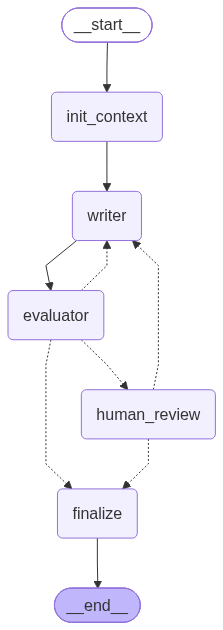

저장: ppt_assets/task1_graph.png


In [11]:
save_graph(app, "ppt_assets/task1_graph.png")

In [12]:
def run(inp, config, context):
    """invoke 후 interrupt 가 걸렸으면 대기 내용을 로그로 남김"""
    result = app.invoke(inp, config=config, context=context)
    if "__interrupt__" in result:
        p = result["__interrupt__"][0].value
        logger.info("[INTERRUPT] human_review 대기 | %s | 최고 %d점 | 점수 추이 %s",
                    p["message"], p["best_score"], p["score_history"])
    return result

## 7. 실행 ① 기본 시나리오 (기준 80점, 최대 3회)

In [13]:
logger.info("===== 시나리오 1: 기준 80점 / 최대 3회 =====")
ctx1 = ReportContext(topic="2026 Z세대 숏폼 커머스 마케팅 트렌드",
                     target_audience="뷰티 브랜드 마케팅 팀장(예산·채널 의사결정자)")
result1 = run({"stage": "start"}, {"configurable": {"thread_id": "report-1"}}, ctx1)
print(f"\n최종 단계: {result1['stage']} | 확정본 점수: {result1['best_score']} | 점수 추이: {result1['score_history']} | LLM 호출: {result1['llm_calls']}")

10:06:07 | INFO    | ===== 시나리오 1: 기준 80점 / 최대 3회 =====


10:06:07 | INFO    | [init_context] 주제=2026 Z세대 숏폼 커머스 마케팅 트렌드 | 타깃=뷰티 브랜드 마케팅 팀장(예산·채널 의사결정자) | 기준 80점 | 최대 3회


10:06:07 | INFO    | [writer] 1회차 초안 작성 시작


10:06:15 | INFO    | [writer] 완료 | 1785자 | stage initialized -> drafted | loop_count 0 -> 1


10:06:17 | INFO    | [evaluator] 1회차 | 종합 88 (논리 90 / 완성 85 / 타깃 88) | 기준 80


...

10:06:17 | INFO    |     보완3: 본론 3번 사례에 브랜드명이나 구체적 캠페인명 추가로 신뢰도 강화


10:06:17 | INFO    | [evaluator] stage drafted -> evaluated | score 0 -> 88 | best_score -1 -> 88


10:06:17 | INFO    | [router] 88 >= 80 -> finalize (통과)


10:06:17 | INFO    | [finalize] stage -> approved | 확정본 88점 | 점수 추이 [88] | 작성 1회 | LLM 호출 2회



최종 단계: approved | 확정본 점수: 88 | 점수 추이: [88] | LLM 호출: 2


In [14]:
from IPython.display import Markdown
display(Markdown(result1["final_report"]))

# 2026 Z세대 숏폼 커머스 마케팅 트렌드 보고서

## 서론

Z세대는 디지털 네이티브로서 짧고 간결한 콘텐츠 소비에 익숙하며, 숏폼 영상 플랫폼을 통해 정보와 쇼핑을 동시에 경험하는 새로운 소비 행태를 보이고 있습니다. 2026년을 맞아 뷰티 브랜드가 Z세대와 효과적으로 소통하기 위해서는 숏폼 커머스 전략을 최적화하는 것이 필수적입니다. 본 보고서에서는 Z세대 숏폼 커머스 마케팅의 최신 트렌드 3가지를 분석하고, 뷰티 브랜드 마케팅 팀장님께서 예산과 채널 선정에 참고할 수 있는 시사점을 제시하고자 합니다.

## 본론

### 1. 인플루언서 협업에서 '마이크로·나노 인플루언서' 중심으로 이동

기존 대형 인플루언서 중심 마케팅에서 벗어나, 팔로워 수는 적지만 타깃과 밀접한 관계를 형성한 마이크로·나노 인플루언서가 주목받고 있습니다. 이들은 신뢰도와 참여도가 높아 숏폼 콘텐츠 내에서 자연스럽고 진정성 있는 제품 소개가 가능하며, 비용 대비 효율이 뛰어납니다.

**사례:** 한 뷰티 브랜드는 팔로워 5만 이하의 뷰티 크리에이터들과 협업해 신제품 론칭 영상 시리즈를 제작했고, 기존 대형 인플루언서 캠페인 대비 전환율이 30% 이상 상승했습니다.

**시사점:** 예산 배분 시 대형 인플루언서에 집중하기보다, 여러 마이크로 인플루언서와 다각도로 협업하는 전략이 효과적입니다. 각 채널별 타깃 세분화와 메시지 맞춤화가 필요합니다.

### 2. 쇼트폼 영상 내 '인터랙티브 커머스' 도입 확대

Z세대는 단순 시청에 머무르지 않고, 영상 속에서 바로 제품을 구매하거나 이벤트에 참여하고 싶어하는 경향이 강합니다. 이에 따라 쇼트폼 플랫폼은 영상 내 바로 구매 가능한 인터랙티브 기능을 강화하고 있으며, 이는 구매 전환율 증가로 이어지고 있습니다.

**사례:** 한 글로벌 뷰티 브랜드는 틱톡의 ‘쇼핑 태그’ 기능을 활용해 메이크업 튜토리얼 영상에 제품 태그를 삽입, 영상 시청 후 즉시 구매가 가능하도록 하여 매출이 40% 증가하였습니다.

**시사점:** 숏폼 영상 제작 시 인터랙티브 요소를 적극 도입해 단순 콘텐츠 소비를 넘어 즉각적인 구매 유도로 연결해야 합니다. 플랫폼별 기능 차이를 고려한 채널별 최적화가 요구됩니다.

### 3. '스토리텔링과 진정성'을 강조한 브랜드 메시지

Z세대는 가치 소비를 중요시하며, 단순 제품 홍보보다 브랜드의 철학과 진정성을 담은 스토리텔링에 공감합니다. 숏폼 영상은 짧은 시간 안에 강렬한 메시지를 전달할 수 있는 장점이 있어, 브랜드의 사회적 책임, 친환경 소재 사용 등 진정성 있는 내용을 강조하는 사례가 늘고 있습니다.

**사례:** 한 뷰티 브랜드는 재생 플라스틱을 활용한 제품 출시와 관련된 제작 과정을 숏폼 영상으로 제작, 투명한 메시지를 전하며 Z세대의 충성도를 높였습니다.

**시사점:** 마케팅 예산 중 일부를 브랜드 스토리텔링 콘텐츠 제작에 배정하고, 진정성 있는 메시지를 지속적으로 전달해야 합니다. 이는 장기적 브랜드 이미지 구축과 고객 충성도 향상에 기여합니다.

## 결론

2026년 Z세대 숏폼 커머스 마케팅은 마이크로 인플루언서 중심 협업, 인터랙티브 커머스 기능 활용, 그리고 진정성 있는 스토리텔링을 결합한 전략이 핵심입니다. 뷰티 브랜드 마케팅 팀장님께서는 이 세 가지 트렌드를 기반으로 예산과 채널을 재조정하여, Z세대 소비자와의 효과적인 소통과 매출 증대에 집중할 필요가 있습니다. 특히, 다양한 규모의 인플루언서와 협업하고, 숏폼 플랫폼별 인터랙티브 기능을 적극 활용하며, 브랜드 철학을 담은 진정성 있는 콘텐츠 제작에 투자하는 것이 성공적인 마케팅 전략의 열쇠가 될 것입니다.

## 8. 실행 ② 예외 시나리오 (기준 95점 → 자동 반복 소진 → 사람 검토)
자동 3회로 기준을 넘지 못하면 `human_review` 에서 멈춘다. 검토자는 수정 지시(revise)를 한 번 내리고, 그래도 미달이면 최고점 원고로 승인(approve)한다.

In [15]:
logger.info("===== 시나리오 2: 기준 95점 / 최대 3회 (반복 소진 -> 사람 검토) =====")
cfg2 = {"configurable": {"thread_id": "report-2"}}
ctx2 = ReportContext(topic="생성형 AI 기반 초개인화 CRM 마케팅",
                     target_audience="중소 이커머스 대표(마케팅 비전문가)", pass_score=95, max_loops=3)
result2 = run({"stage": "start"}, cfg2, ctx2)

10:06:17 | INFO    | ===== 시나리오 2: 기준 95점 / 최대 3회 (반복 소진 -> 사람 검토) =====


10:06:17 | INFO    | [init_context] 주제=생성형 AI 기반 초개인화 CRM 마케팅 | 타깃=중소 이커머스 대표(마케팅 비전문가) | 기준 95점 | 최대 3회


10:06:17 | INFO    | [writer] 1회차 초안 작성 시작


10:06:23 | INFO    | [writer] 완료 | 1779자 | stage initialized -> drafted | loop_count 0 -> 1


10:06:25 | INFO    | [evaluator] 1회차 | 종합 80 (논리 85 / 완성 75 / 타깃 80) | 기준 95


...

10:06:55 | INFO    |     보완2: 본론 각 사례의 출처 표기를 통일하고, 외부 공개 자료나 통계 출처를 추가해 신뢰성 보완 필요(예: ‘스타일온’ 내부 데이터 ...


10:06:55 | INFO    |     보완3: 도입 방법에서 예상 소요 기간과 비용은 제시했으나, 초기 실패 사례나 리스크 관리 방안이 부족해 현실적 조언 보완 권장


10:06:55 | INFO    | [evaluator] stage drafted -> evaluated | score 88 -> 92 | best_score 88 -> 92


10:06:55 | WARNING | [router] 92 < 95, 작성 3회로 자동 반복 소진 -> human_review


10:06:55 | INFO    | [INTERRUPT] human_review 대기 | 자동 검수 기준 미달. approve(최고점 원고로 확정) 또는 revise(+feedback 수정 지시)를 입력하세요. | 최고 92점 | 점수 추이 [80, 88, 92]


In [16]:
# 검토자 수정 지시 1회
result2 = run(Command(resume={"action": "revise",
                              "feedback": "분량을 1,500자 내외로 줄이고, 트렌드마다 바로 쓸 수 있는 도구 1개와 월 예상 비용을 넣을 것"}),
              cfg2, ctx2)
if "__interrupt__" in result2:   # 그래도 미달이면 최고점 원고로 승인
    result2 = run(Command(resume={"action": "approve"}), cfg2, ctx2)
print(f"\n최종 단계: {result2['stage']} | 확정본 점수: {result2['best_score']} | 점수 추이: {result2['score_history']} | 작성 {result2['loop_count']}회 | LLM 호출 {result2['llm_calls']}")

10:06:55 | INFO    | [human_review] 검토자 결정 revise | 지시: 분량을 1,500자 내외로 줄이고, 트렌드마다 바로 쓸 수 있는 도구 1개와 월 예상 비용을 넣을 것


10:06:55 | INFO    | [writer] 4회차 수정본 작성 시작


10:07:06 | INFO    | [writer] 완료 | 3328자 | stage human_revise -> drafted | loop_count 3 -> 4


10:07:09 | INFO    | [evaluator] 4회차 | 종합 88 (논리 90 / 완성 85 / 타깃 88) | 기준 95


10:07:09 | INFO    |     보완1: 서론에서 생성형 AI와 초개인화 CRM의 개념 설명을 좀 더 쉽게 풀어 중소기업 비전문가가 이해하기 쉽도록 개선할 것


...

10:07:09 | WARNING | [router] 88 < 95, 작성 4회로 자동 반복 소진 -> human_review


10:07:09 | INFO    | [INTERRUPT] human_review 대기 | 자동 검수 기준 미달. approve(최고점 원고로 확정) 또는 revise(+feedback 수정 지시)를 입력하세요. | 최고 92점 | 점수 추이 [80, 88, 92, 88]


10:07:09 | INFO    | [human_review] 검토자 결정 approve | 최고점 92점 원고로 확정


10:07:09 | INFO    | [finalize] stage -> approved_by_human | 확정본 92점 | 점수 추이 [80, 88, 92, 88] | 작성 4회 | LLM 호출 8회



최종 단계: approved_by_human | 확정본 점수: 92 | 점수 추이: [80, 88, 92, 88] | 작성 4회 | LLM 호출 8


## 9. 라우팅 로직 자체 점검 (LLM 호출 없음)

In [17]:
logger.info("===== 라우팅 단위 점검 =====")
assert route_after_evaluation({"score": 85, "pass_score": 80, "loop_count": 1, "max_loops": 3}) == "finalize"
assert route_after_evaluation({"score": 70, "pass_score": 80, "loop_count": 1, "max_loops": 3}) == "writer"
assert route_after_evaluation({"score": 70, "pass_score": 80, "loop_count": 3, "max_loops": 3}) == "human_review"
assert result2["best_score"] == max(result2["score_history"]), "확정본은 최고점 원고여야 함"
print("점검 통과 (로그 파일: ppt_assets/task1_run.log)")

10:07:09 | INFO    | ===== 라우팅 단위 점검 =====


10:07:09 | INFO    | [router] 85 >= 80 -> finalize (통과)


10:07:09 | INFO    | [router] 70 < 80 -> writer 재작성 (2/3)


10:07:09 | WARNING | [router] 70 < 80, 작성 3회로 자동 반복 소진 -> human_review


점검 통과 (로그 파일: ppt_assets/task1_run.log)
